In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
from scipy import stats
import openpyxl
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf

# Lectura de datos 

valores = pd.read_excel(data/tipoCambio.xls)
valores = valores.copy()

valores = valores.drop(columns=("Unnamed: 2"))
valores = valores.drop(columns=("Unnamed: 3"))
valores = valores.drop([0,1,2,3,4,5,6],axis=0)

valores = valores.loc[valores["Unnamed: 1"] != "N/E"]

valores["Unnamed: 1"] = pd.to_numeric(valores["Unnamed: 1"] , errors="coerce")
valores = valores.rename(columns={"Tipo de cambio para solventar obligaciones denominadas en dólares de los EE.UU.A.,\npagaderas en la República Mexicana" : "Fecha"})
valores = valores.rename(columns={"Unnamed: 1": "Tipo de cambio"})

valores["Fecha"] = pd.to_datetime(valores["Fecha"], format="%d/%m/%Y")

valores = valores.reset_index(drop=True)

valores

,Fecha,Tipo de cambio
0,2005-01-03,11.2007
1,2005-01-04,11.3087
2,2005-01-05,11.3418
3,2005-01-06,11.4018
4,2005-01-07,11.3643
...,...,...
5278,2025-12-24,17.9248
5279,2025-12-26,17.9042
5280,2025-12-29,17.9667
5281,2025-12-30,17.9528


# fase 2 Retornos y graficas de precio

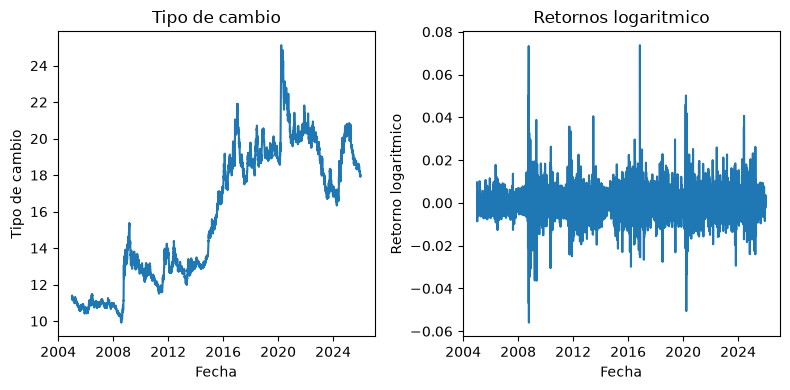

In [6]:
tipo_cambio = valores["Tipo de cambio"]

retornos_log = np.log(tipo_cambio).diff()


fig, ax = plt.subplots(1,2,figsize=(8,4))
ax[0].plot(valores["Fecha"],valores["Tipo de cambio"])
ax[0].set_title("Tipo de cambio")
ax[0].set_ylabel("Tipo de cambio")
ax[0].set_xlabel("Fecha")

ax[1].plot(valores["Fecha"],retornos_log)
ax[1].set_title("Retornos logaritmico")
ax[1].set_ylabel("Retorno logaritmico")
ax[1].set_xlabel("Fecha")

plt.tight_layout()
plt.show()




# fase 3 descriptivos

In [19]:
# Eliminar nulo de los retornos logaritmicos
retornos_log = retornos_log.dropna()
valores["retornos logaritmicos"] = retornos_log
# Calculos
retornos_log_mean = retornos_log.mean()
retornos_log_desv = retornos_log.std()
retornos_log_skew = stats.skew(retornos_log) 
retornos_log_kurtosis = stats.kurtosis(retornos_log)

# Dias de que superen mas de 3,4,5 desviaciones

x = np.abs(retornos_log)

days_3desv = (x > (retornos_log_desv * 3)).sum()
days_4desv = (x > (retornos_log_desv * 4)).sum()
days_5desv = (x > (retornos_log_desv * 5)).sum()

print(retornos_log_desv,
    days_3desv,
    days_4desv,
    days_5desv)

# dias esperados en una distribucion normal por cada desviacion

dias_desv_esperado3 = (stats.norm.sf(3)*2)*5283
dias_desv_esperado4 = (stats.norm.sf(4)*2)*5283
dias_desv_esperado5 = (stats.norm.sf(5)*2)*5283

print(dias_desv_esperado3,
      dias_desv_esperado4,
      dias_desv_esperado5)

# Tabla K
tabla = pd.DataFrame({
    "k":[3,4,5],
    "observados":[days_3desv,days_4desv,days_5desv],
    "esperados":[dias_desv_esperado3,dias_desv_esperado4,dias_desv_esperado5]
})

tabla["razon"] = tabla["observados"] / tabla["esperados"]


print(retornos_log_mean,
      retornos_log_skew)
tabla


0.00724512420528872 78 35 17
14.263022602203566 0.33463834120874447 0.003028760508475556
8.982622983580135e-05 0.8038329589525147


,k,observados,esperados,razon
0,3,78,14.263023,5.468687
1,4,35,0.334638,104.590526
2,5,17,0.003029,5612.857125



# Fase 4 de normalidad 

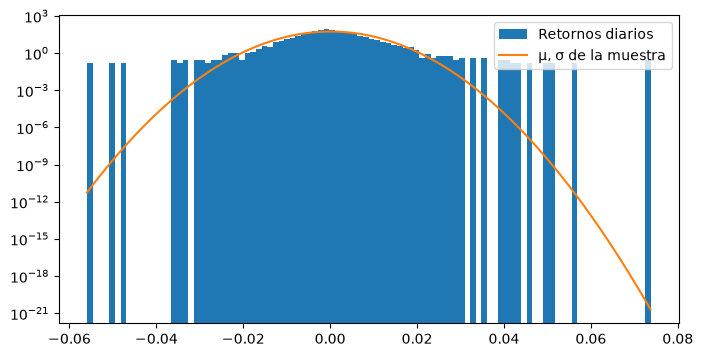

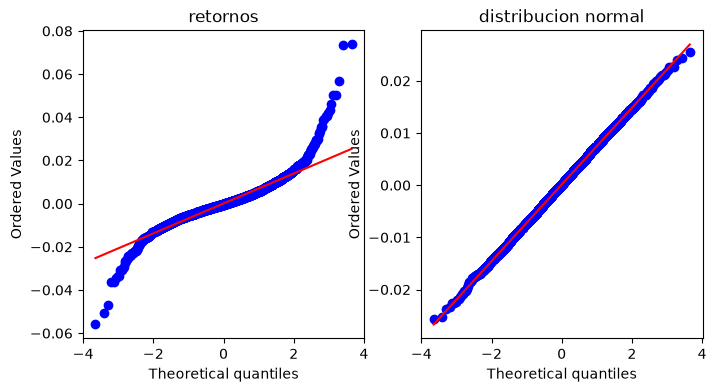

SignificanceResult(statistic=np.float64(22369.64032202804), pvalue=np.float64(0.0))
9.952742985779691


In [8]:

# Grafica histograma
fig, ax = plt.subplots(figsize=(8,4))
plt.hist(retornos_log,bins=100,density=True,label="Retornos diarios")
f = np.linspace(retornos_log.min(), retornos_log.max(), 100)
y = stats.norm.pdf(f,loc=retornos_log_mean,scale=retornos_log_desv)
plt.plot(f,y,label="μ, σ de la muestra")
plt.yscale("log")
plt.legend()
plt.show()


# Grafica QQ
np.random.seed(32)
datos_normal = np.random.normal(retornos_log_mean,retornos_log_desv,5282)
fig, ax = plt.subplots(1,2,figsize=(8,4))
stats.probplot(retornos_log,dist="norm",plot=ax[0])
stats.probplot(datos_normal,dist="norm",plot=ax[1])
ax[0].set_title("retornos")
ax[1].set_title("distribucion normal")
plt.show()
# basandome en los resultados de la grafica Q-Q, la disrtribucion de los retornos log indica que las colas son muy pesadas

prueba_jarque = stats.jarque_bera(retornos_log)
print(prueba_jarque)#p-value = 0.0
print(retornos_log_kurtosis)#9.952742985779691
# el p-value es 0 entonces se rechaza la hipotesis nula los datos no parecen seguir una distribucion normal y por la kustosis que es elevada
# indica colas pesadas 




# Fase 5: Volatilidad móvil

,inicio,fin,vol_max
episodio,,,
1,2008-10-06,2009-01-07,0.454147
2,2009-03-17,2009-03-24,0.194593
3,2009-04-01,2009-04-03,0.190221
4,2009-04-13,2009-04-14,0.187495
5,2009-04-23,2009-06-08,0.222940
6,2010-05-26,2010-06-15,0.191682
7,2011-09-30,2011-09-30,0.189315
8,2011-10-05,2011-11-16,0.238011
9,2011-11-30,2011-12-02,0.196276


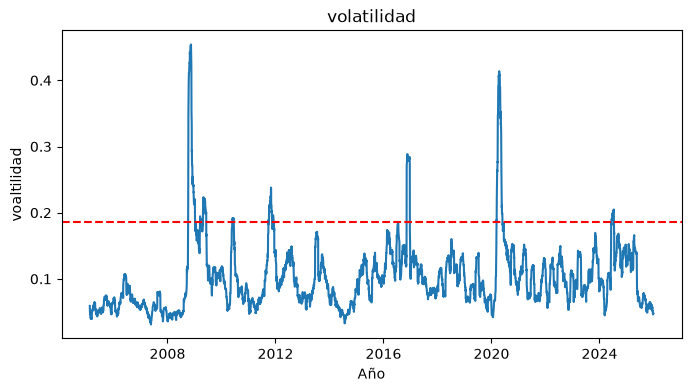

In [9]:

volatilidad_anual_30 = retornos_log.rolling(window=30).std()* np.sqrt(252)
volatilidad_anual_60 = retornos_log.rolling(window=60).std()* np.sqrt(252)
valores["volatilidad anual"] = volatilidad_anual_30# se inserta al dataframe para conicnidir lo largo de lo valores
per_95 = volatilidad_anual_30.quantile(0.95)

fig, ax = plt.subplots(figsize=(8,4))

plt.plot(valores["Fecha"],valores["volatilidad anual"])
ax.set_title("volatilidad")
ax.set_ylabel("voaltilidad")
ax.set_xlabel("Año")
plt.axhline(y=per_95,color="red",linestyle="--")

valores["valores volatiles"] = valores["volatilidad anual"] >= per_95
valores["inicio"]   = valores["valores volatiles"] & ~valores["valores volatiles"].shift(1, fill_value=False)
valores["episodio"] = valores["inicio"].cumsum()


episodios = (
    valores[valores["valores volatiles"]]
    .groupby("episodio")
    .agg(
        inicio=("Fecha", "min"),
        fin=("Fecha", "max"),
        vol_max=("volatilidad anual", "max"),
    )
)

episodios




# Fase 6: Eventos (sin sesgo de confirmación)

In [10]:
# los Episodios se ordenan de descendente por volatildidad
episodios.sort_values(by="vol_max",ascending=False)

# Los 3 episodios que mas destacan son, el primero es la caida de la bolsa en 2008, el segundo es la pandemia, tercero la victoria de trump en 2016, el cuarto no entiendo que paso para 
# que tuviera volatilidad, otro evento que puedo entenderla volatilidad fue en 2024 la eleccion presidencial y la reforma judicial 

,inicio,fin,vol_max
episodio,,,
1,2008-10-06,2009-01-07,0.454147
11,2020-03-09,2020-05-27,0.413789
10,2016-11-09,2016-12-22,0.288516
8,2011-10-05,2011-11-16,0.238011
5,2009-04-23,2009-06-08,0.222940
12,2024-06-12,2024-07-12,0.204854
9,2011-11-30,2011-12-02,0.196276
2,2009-03-17,2009-03-24,0.194593
6,2010-05-26,2010-06-15,0.191682


# Fase 7 Analisis

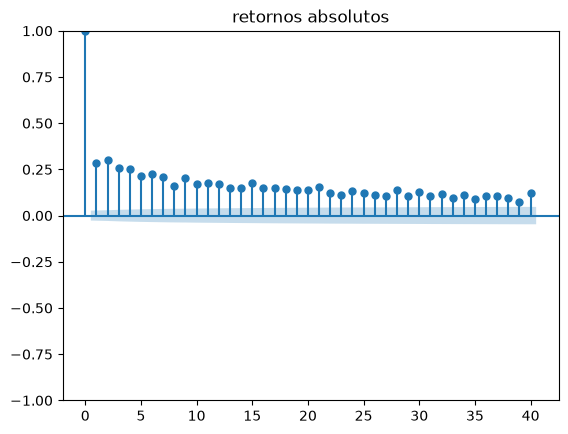

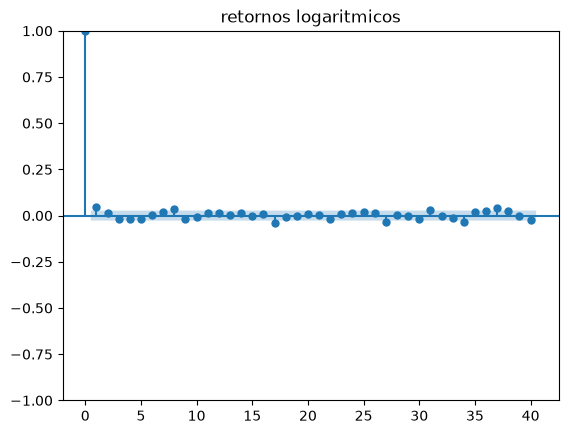

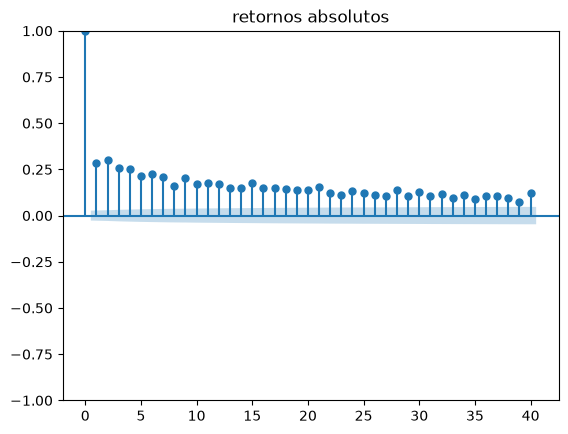

In [11]:
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf

retornos_absolutos = np.abs(retornos_log)

plot_acf(retornos_log,lags=40,title="retornos logaritmicos")
plot_acf(retornos_absolutos,lags=40,title="retornos absolutos")





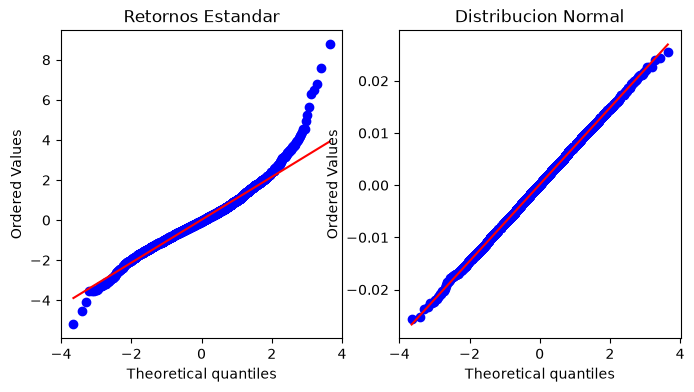

3.004016313610883


In [12]:
# Estandarizar retornos 
volatilidad_previa = retornos_log.rolling(window=30).std().shift(1)
retornos_estandar = (retornos_log / volatilidad_previa).dropna()

retornos_estandar_kurtosis = stats.kurtosis(retornos_estandar)

# Grafiac Q-Q

fig, ax = plt.subplots(1,2, figsize=(8,4))
stats.probplot(retornos_estandar,dist="norm",plot=ax[0])
stats.probplot(datos_normal,dist="norm",plot=ax[1])
ax[0].set_title("Retornos Estandar")
ax[1].set_title("Distribucion Normal")
plt.show()

print(retornos_estandar_kurtosis)


(np.float64(3.4535164828550013), np.float64(-0.00022762735462423172), np.float64(0.00478070418941144))


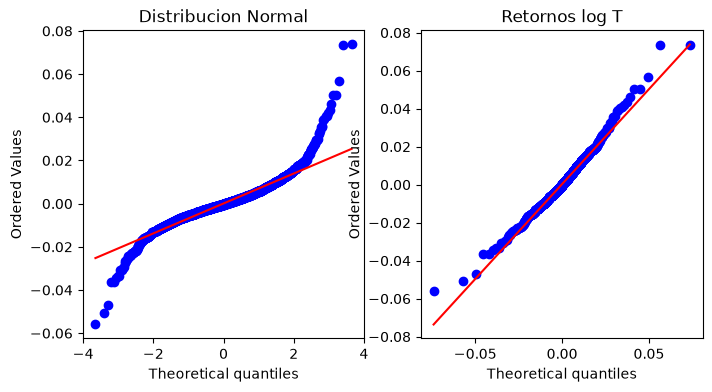

In [13]:
# Grafica Q-Q, T-student
retornos_t = stats.t.fit(retornos_log)
print(retornos_t)

fig, ax = plt.subplots(1,2,figsize=(8,4))

stats.probplot(retornos_log,dist="norm",plot=ax[0])
stats.probplot(retornos_log,dist="t",plot=ax[1],sparams=retornos_t)
ax[1].set_title("Retornos log T")
ax[0].set_title("Distribucion Normal")
plt.show()
